# Aplicação prática do modelo vencedor

Esta etapa transforma o resultado estatístico em uma leitura concreta: uma observação do teste oficial passa pelo estimator, recebe uma probabilidade calibrada e é comparada com o threshold congelado. O intervalo de Wilson será usado somente para a proporção observada de um grupo, não como intervalo de confiança individual.

## 1. Contrato da aplicação

A pergunta desta seção é: como o modelo final transforma as características de uma observação em uma decisão sobre o alvo `renda >50K`? O exemplo não altera o treinamento, o calibrador, o threshold ou o resultado da avaliação final. Ele apenas aplica o protocolo congelado a uma linha escolhida de forma determinística.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from adult_data import load_adult
from practical_application import write_practical_case_outputs

selection_contract_path = ROOT / 'data' / 'processed' / 'selection' / 'threshold_selection_contract.json'
output_dir = ROOT / 'data' / 'processed' / 'case_study'
data = load_adult(ROOT / 'data' / 'raw' / 'adult_uci')
outputs = write_practical_case_outputs(data, selection_contract_path, output_dir)
contract = json.loads(outputs['contract'].read_text(encoding='utf-8'))
{key: contract[key] for key in ['model', 'threshold', 'source_split', 'source_row_index', 'row_selector', 'test_case_study_post_evaluation']}

{'model': 'hist_gradient_boosting',
 'threshold': 0.31,
 'source_split': 'test_official',
 'source_row_index': 32617,
 'row_selector': 'closest_to_threshold',
 'test_case_study_post_evaluation': True}

### Insights:
O protocolo mantém o teste oficial fora de treinamento e seleção. A linha é usada apenas como um caso ilustrativo pós-avaliação, escolhido por estar mais próxima do threshold e, portanto, tornar visível a diferença entre uma decisão limítrofe e uma certeza individual.

## 2. Uma observação aplicada ao estimator

O alvo é binário: `>50K` ou `≤50K`. O estimator não estima o valor exato da renda. Primeiro ele produz uma probabilidade calibrada de pertencer à classe `>50K`; depois o threshold transforma essa probabilidade em uma decisão operacional do experimento.

In [2]:
case = pd.read_csv(outputs['case'])
display(case.T.rename(columns={0: 'valor'}))

display(case[[
    'model', 'threshold', 'raw_probability', 'calibrated_probability',
    'predicted_label', 'actual_label', 'prediction_correct'
]].round(4))

,valor
age,63
workclass,Private
fnlwgt,145985
education,HS-grad
education_num,9
marital_status,Married-civ-spouse
occupation,Craft-repair
relationship,Husband
capital_gain,0
capital_loss,0


,model,threshold,raw_probability,calibrated_probability,predicted_label,actual_label,prediction_correct
0,hist_gradient_boosting,0.31,0.3013,0.3104,>50K,<=50K,False


### Insights:
Para a observação selecionada, a probabilidade calibrada é aproximadamente `0,3104`. Como ela está ligeiramente acima do threshold `0,31`, o modelo decide `>50K`. O rótulo observado, porém, foi `≤50K`. Esse desacordo não é uma contradição do modelo: uma probabilidade de 31% representa incerteza e admite que muitos casos semelhantes não pertençam à classe positiva.

## 3. Onde entra o intervalo de Wilson em um grupo

Para não confundir incertezas diferentes, escolhemos previamente o grupo `sex = Female` no teste oficial. Calculamos a proporção observada de casos `>50K` no grupo e seu intervalo de Wilson de 95%. Em paralelo, calculamos a média das probabilidades calibradas previstas para as mulheres. O intervalo pertence à proporção observada do grupo; não é uma faixa de renda nem um intervalo de confiança da média prevista ou de uma pessoa.

In [3]:
group_summary = pd.read_csv(outputs['group_summary'])
display(group_summary[[
    'audit_column', 'group', 'count', 'positive_count',
    'observed_target_rate', 'wilson_ci_low', 'wilson_ci_high',
    'mean_calibrated_probability', 'mean_probability_inside_wilson_interval'
]].round(4))

,audit_column,group,count,positive_count,observed_target_rate,wilson_ci_low,wilson_ci_high,mean_calibrated_probability,mean_probability_inside_wilson_interval
0,sex,Female,5421,590,0.1088,0.1008,0.1174,0.1196,False


### Insights:
No grupo `sex = Female`, a taxa observada de `>50K` foi `10,88%`, com IC de Wilson de 95% entre `10,08%` e `11,74%`. A média das probabilidades calibradas foi `11,96%`, ligeiramente acima do limite superior. Isso sugere uma pequena sobre-estimação agregada no snapshot; não garante a classificação de nenhuma pessoa nem demonstra ausência de viés.

## 4. Visualização da calibração agregada do grupo

O gráfico coloca na mesma escala a média das probabilidades calibradas do grupo, o threshold e a taxa observada do alvo. A barra representa o intervalo de Wilson da proporção binomial observada no grupo.

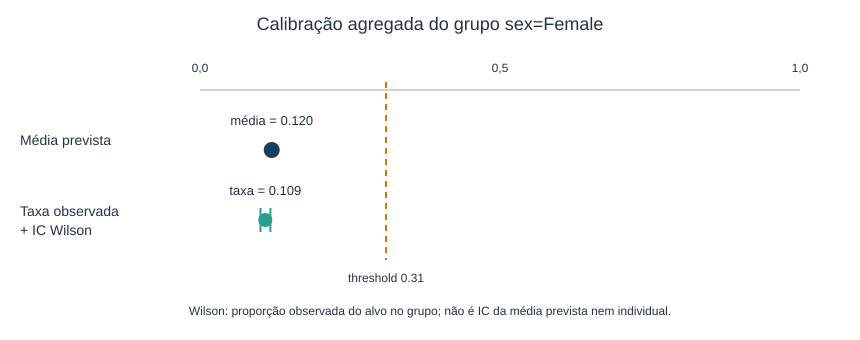

In [4]:
display(SVG(filename=str(outputs['svg'])))

### Insights:
A média prevista do grupo pode ser comparada ao intervalo de Wilson da sua taxa observada, mas as duas quantidades têm papéis diferentes: a primeira resume scores do modelo e a segunda resume rótulos binários observados. O threshold acrescenta a regra decisória, enquanto o intervalo comunica a incerteza da proporção do grupo. Nenhuma dessas medidas transforma a previsão em certeza individual.

## 5. Limitações da demonstração

Este exemplo usa uma única linha do teste oficial somente depois de o modelo, calibrador e threshold terem sido congelados. O alvo observado é usado para interpretar o caso, não para treinar, selecionar ou ajustar o modelo. O dataset é histórico, o rótulo `>50K` é uma classificação censitária e o resultado não deve ser usado para decisões reais de crédito, emprego, benefícios ou triagem.

### Insights:
A aplicação prática responde como o estimator opera sobre uma observação e como seu comportamento médio pode ser confrontado com uma proporção observada de grupo. A interpretação mais defensável combina a probabilidade da linha, o threshold explicitamente escolhido, o rótulo observado, a média dos scores do grupo e o intervalo de Wilson da proporção binária observada.